# 02 Population: where potential visitors live

**Data.** Kontur Population (HDX, CC BY 4.0) estimates the number of residents in 400 m hexagons of the H3 grid, built from satellite settlement data (GHSL), Facebook population maps and OpenStreetMap. One country file covers all of Russia, so we read only the part we need.

**Study area.** The market is residents of St Petersburg and Leningrad Oblast travelling by car, plus the parts of Pskov and Novgorod oblasts within `BORDER_KM` of the Leningrad Oblast border. Region boundaries come from OpenStreetMap (© OpenStreetMap contributors) via osmnx.

**CRS.** Raw data is in degrees. Distances, buffers and grid cells are computed in UTM zone 36N (EPSG:32636), a projection in metres suited to north-west Russia.

**Origins.** 400 m hexagons are too many for a travel time matrix, so they are summed into coarse cells of `CELL_KM` km. Each cell becomes one origin, placed at its population-weighted centre.

In [1]:
import os, glob, gzip, shutil
import pandas as pd
import geopandas as gpd
import pyogrio
import osmnx as ox
import matplotlib.pyplot as plt

RAW = "../data/raw"
PROCESSED = "../data/processed"

CRS_M = "EPSG:32636"   # UTM zone 36N, metres
BORDER_KM = 50         # reach into Pskov and Novgorod oblasts
CELL_KM = 5            # size of the coarse origin cells

In [2]:
# Unpack .gpkg.gz -> .gpkg once (a GeoPackage must be unpacked to be read quickly)
gpkg_files = glob.glob(os.path.join(RAW, "kontur_population_RU_*.gpkg"))
gz_files = glob.glob(os.path.join(RAW, "kontur_population_RU_*.gpkg.gz"))

if not gpkg_files:
    if not gz_files:
        raise FileNotFoundError("Put kontur_population_RU_*.gpkg.gz into data/raw first")
    src = gz_files[0]
    dst = src[:-3]
    print("Unpacking", src, "(takes a minute or two)")
    with gzip.open(src, "rb") as f_in, open(dst, "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)
    gpkg_files = [dst]

KONTUR = gpkg_files[0]
print(KONTUR, round(os.path.getsize(KONTUR) / 1e6), "MB")

# Look inside without loading: CRS, number of hexagons, column names
info = pyogrio.read_info(KONTUR)
print("CRS:", info["crs"])
print("Hexagons:", info["features"])
print("Columns:", list(info["fields"]))

Unpacking ../data/raw\kontur_population_RU_20231101.gpkg.gz (takes a minute or two)
../data/raw\kontur_population_RU_20231101.gpkg 181 MB
CRS: EPSG:3857
Hexagons: 926647
Columns: ['h3', 'population']


                          region  area_km2
0               Saint Petersburg    2284.0
1               Leningrad Oblast   94868.0
2     Pskov Oblast (border part)    8357.0
3  Novgorod Oblast (border part)   20019.0


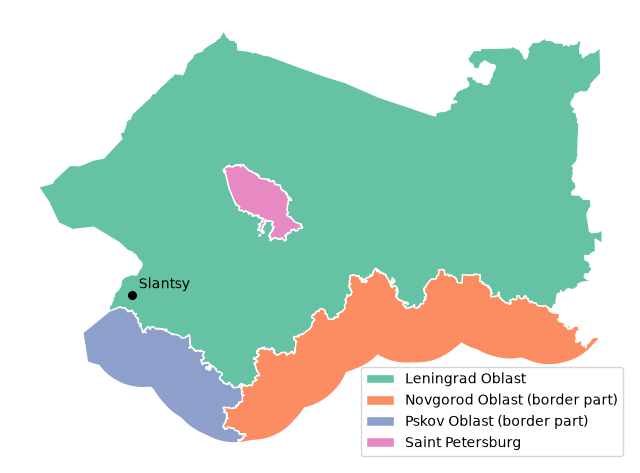

In [3]:
# Region boundaries from OpenStreetMap, cached in data/raw
REGIONS = {
    "Saint Petersburg": "Санкт-Петербург, Россия",
    "Leningrad Oblast": "Ленинградская область, Россия",
    "Pskov Oblast": "Псковская область, Россия",
    "Novgorod Oblast": "Новгородская область, Россия",
}
regions_path = os.path.join(RAW, "regions_osm.geojson")

if os.path.exists(regions_path):
    regions = gpd.read_file(regions_path)
else:
    parts = [ox.geocode_to_gdf(q)[["geometry"]].assign(region=name) for name, q in REGIONS.items()]
    regions = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs="EPSG:4326")
    regions.to_file(regions_path, driver="GeoJSON")

# Work in metres
reg = regions.to_crs(CRS_M).set_index("region")["geometry"]
spb = reg["Saint Petersburg"]
lo = reg["Leningrad Oblast"].difference(spb)        # make sure SPb is not counted twice

# Border zone: everything within BORDER_KM of SPb + Leningrad Oblast
core = spb.union(lo).simplify(500)                  # simplify first so the buffer is fast
zone = core.buffer(BORDER_KM * 1000)
pskov = reg["Pskov Oblast"].intersection(zone)
novg = reg["Novgorod Oblast"].intersection(zone)

study = gpd.GeoDataFrame(
    {"region": ["Saint Petersburg", "Leningrad Oblast",
                "Pskov Oblast (border part)", "Novgorod Oblast (border part)"]},
    geometry=[spb, lo, pskov, novg], crs=CRS_M)
study["area_km2"] = (study.area / 1e6).round()
print(study[["region", "area_km2"]])

# Check map, Slantsy marked for orientation
slantsy = gpd.GeoSeries(gpd.points_from_xy([28.09], [59.12]), crs="EPSG:4326").to_crs(CRS_M)
ax = study.plot(column="region", cmap="Set2", edgecolor="white", legend=True,
                figsize=(8, 8), legend_kwds={"loc": "lower right"})
slantsy.plot(ax=ax, color="black", markersize=30)
ax.annotate("Slantsy", (slantsy.x[0], slantsy.y[0]), xytext=(5, 5), textcoords="offset points")
ax.set_axis_off()
plt.show()